In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from scipy.stats import shapiro
from scipy.stats import kstest
import seaborn as sns
from sklearn.metrics import confusion_matrix
import warnings
warnings.simplefilter("ignore")


In [19]:
df_train_secu=pd.read_csv("trainning_prima.csv")

In [20]:
df_train_secu.shape

(350045, 26)

In [21]:
#analisis exploratorio
df_train_secu.head()

,curp,cct,turno,ciclo,grado,sexo_bin,categoroia_poblacion,tipo_movimiento,promedio_general,parciales_reprobados_b1,...,faltas_b2,faltas_b3,faltas_totales,materias_repro,extra_edad,alumno_migrante,repetidor,necesidad_edu_esp,reinscrito,abandono
0,AAAA120530MCLLGLA7,05DPR0275G,1,2024-2025,6,1,0,A,6.150,0,...,0,0,0,0,0.0,0.0,0.0,0.0,1,0
1,AAAA121002MCLLLLA2,05DPR0768S,2,2024-2025,5,1,0,A,3.900,0,...,0,0,0,0,2.0,0.0,0.0,0.0,1,0
2,AAAA121023HCLNNNA9,05DPR0408G,1,2024-2025,6,0,1,A,7.225,0,...,5,11,25,0,0.0,0.0,0.0,0.0,1,0
3,AAAA121125MCSLNLA8,05EPR0150Y,2,2024-2025,6,1,0,A,8.325,0,...,0,0,0,0,0.0,0.0,0.0,0.0,1,0
4,AAAA130120MQTLLLA9,05DPR1804N,2,2024-2025,6,1,0,A,9.650,0,...,0,0,0,0,0.0,0.0,0.0,0.0,1,0


In [22]:
df_train_secu.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350045 entries, 0 to 350044
Data columns (total 26 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   curp                     350045 non-null  object 
 1   cct                      350045 non-null  object 
 2   turno                    350045 non-null  int64  
 3   ciclo                    350045 non-null  object 
 4   grado                    350045 non-null  int64  
 5   sexo_bin                 350045 non-null  int64  
 6   categoroia_poblacion     350045 non-null  int64  
 7   tipo_movimiento          350045 non-null  object 
 8   promedio_general         344152 non-null  float64
 9   parciales_reprobados_b1  350045 non-null  int64  
 10  parciales_reprobados_b2  350045 non-null  int64  
 11  parciales_reprobados_b3  350045 non-null  int64  
 12  calif_bim1               350029 non-null  float64
 13  calif_bim2               347059 non-null  float64
 14  cali

In [23]:
df_train_secu.describe()

,turno,grado,sexo_bin,categoroia_poblacion,promedio_general,parciales_reprobados_b1,parciales_reprobados_b2,parciales_reprobados_b3,calif_bim1,calif_bim2,...,faltas_b2,faltas_b3,faltas_totales,materias_repro,extra_edad,alumno_migrante,repetidor,necesidad_edu_esp,reinscrito,abandono
count,350045.000000,350045.000000,350045.000000,350045.000000,344152.000000,350045.0,350045.0,350045.0,350029.000000,347059.000000,...,350045.000000,350045.000000,350045.000000,350045.0,350038.000000,350038.000000,350038.000000,350038.000000,350045.000000,350045.000000
mean,1.195875,3.363002,0.492071,0.083624,8.226937,0.0,0.0,0.0,8.091142,8.234184,...,3.158011,3.485792,9.207893,0.0,0.016067,0.000086,0.002920,0.002448,0.942864,0.028551
std,0.396873,1.716658,0.499938,0.276823,1.433374,0.0,0.0,0.0,1.529164,1.552553,...,6.027731,6.792466,14.843339,0.0,0.146861,0.009257,0.053955,0.049420,0.232102,0.166540
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,0.000000,0.000000,7.550000,0.0,0.0,0.0,7.500000,7.500000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,1.000000,3.000000,0.000000,0.000000,8.450000,0.0,0.0,0.0,8.250000,8.500000,...,0.000000,0.000000,3.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,1.000000,5.000000,1.000000,0.000000,9.200000,0.0,0.0,0.0,9.000000,9.250000,...,4.000000,4.000000,13.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,2.000000,6.000000,1.000000,1.000000,10.000000,0.0,0.0,0.0,10.000000,10.000000,...,64.000000,69.000000,187.000000,0.0,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [24]:
print("media general:",df_train_secu["promedio_general"].mean())
print("mediana:",df_train_secu["promedio_general"].median())
print("desviacion estandard:",df_train_secu["promedio_general"].std())

media general: 8.226937298054347
mediana: 8.45
desviacion estandard: 1.4333741649507947


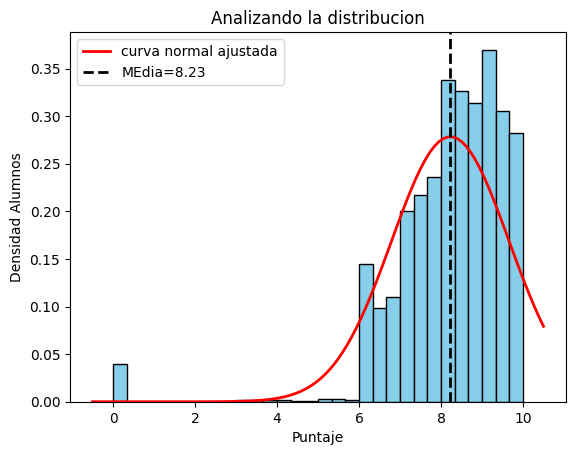

In [25]:
#visualizacion
x=df_train_secu["promedio_general"].dropna().values
#histograma
plt.hist(x,bins=30,color="skyblue",edgecolor="black",density=True)
#curva normal ajustada
mu,sigma=np.mean(x),np.std(x)
xmin,xmax = plt.xlim()
xvals=np.linspace(xmin,xmax,100)
p=norm.pdf(xvals,mu,sigma)
plt.plot(xvals,p,'r',linewidth=2,label="curva normal ajustada")
plt.axvline(mu,color="black",linestyle="--",linewidth=2,label=f"MEdia={mu:.2f}")
plt.title("Analizando la distribucion")
plt.xlabel("Puntaje")
plt.ylabel("Densidad Alumnos")
plt.legend()
plt.show()

In [26]:
#Shapiro -wilk
#es de las pruebas mas usadas para muestras pequenas y grandes sobre normalidad

stat,p=shapiro(x)
print("Estadistico de shapiro:",stat)
print("p-valor:",p)

if p>0.05:
    print("no se rechaza la normalidad, los datos son normales")
else:
    print("Se rechaza la normalidad")

Estadistico de shapiro: 0.7986755604369387
p-valor: 8.172806363659949e-160
Se rechaza la normalidad


In [27]:
#Komolgorov - Smirnov (K-S)
#compara la distribucion de tus datos con una normal teorica
mu,sigma = np.mean(x),np.std(x)
stat,p=kstest(x,'norm',args=(mu,sigma)) 
print("estadistico de kstest:",stat)
print("p-valor:",p)

if p>0.05:
    print("no se rechaza la normalidad, los datos son normales")
else:
    print("Se rechaza la normalidad")

estadistico de kstest: 0.108045945433064
p-valor: 0.0
Se rechaza la normalidad


In [28]:
#Conteo de la variable objetivo(y) (abandono escolar)
print("\n--- DISTRIBUCIÓN DE ABANDONO ESCOLAR ---")
print(df_train_secu['abandono'].value_counts())
print(df_train_secu['abandono'].value_counts(normalize=True) * 100) # Porcentaje


--- DISTRIBUCIÓN DE ABANDONO ESCOLAR ---
abandono
0    340051
1      9994
Name: count, dtype: int64
abandono
0    97.144939
1     2.855061
Name: proportion, dtype: float64


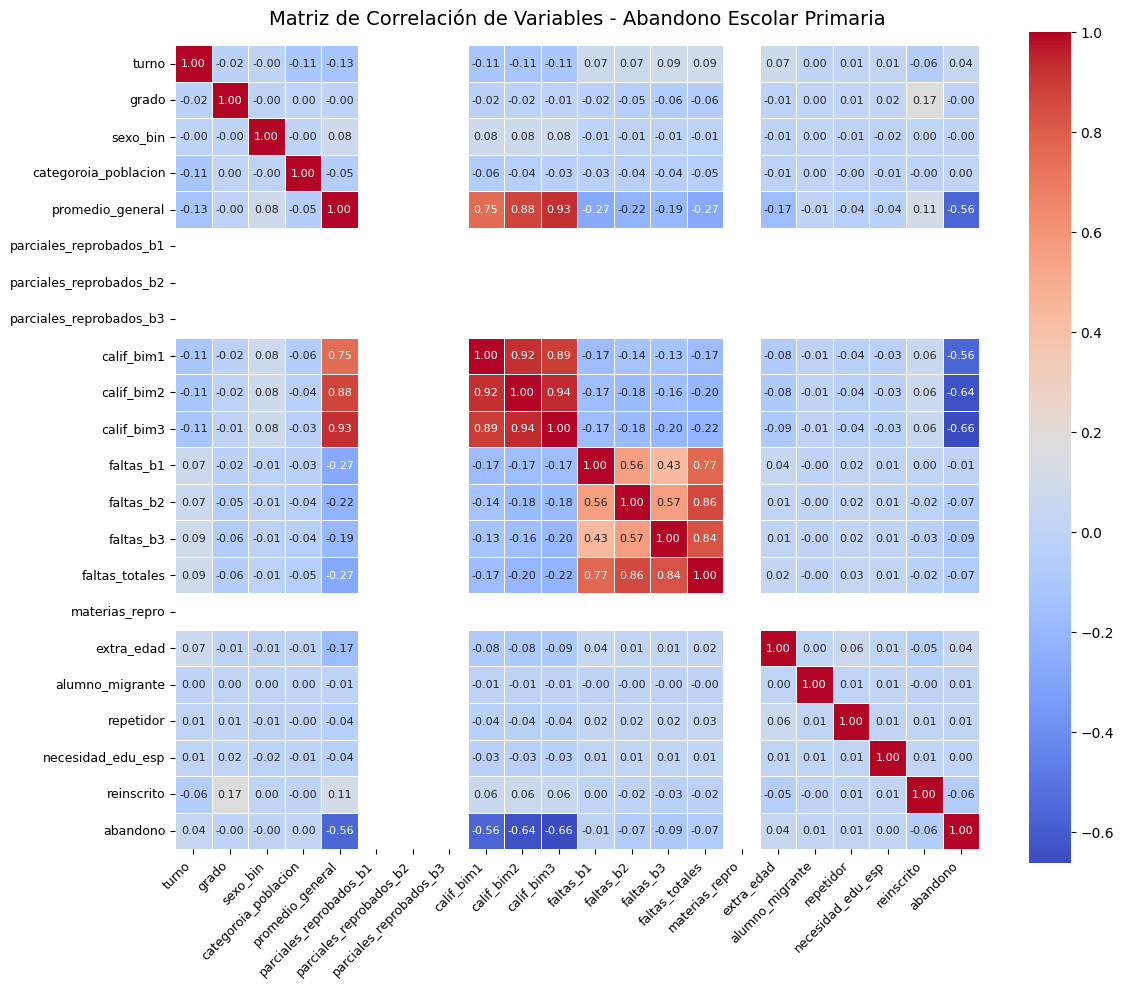

In [29]:
# heatmap Seleccionar únicamente las columnas numéricas
numeric_cols = df_train_secu.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df_train_secu[numeric_cols].corr()

# 3. Configurar y generar el mapa de calor (Heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    annot=True,          # Mostrar los valores numéricos de correlación
    fmt=".2f",           # Formato de dos decimales
    cmap='coolwarm',     # Paleta de colores (rojo = positivo, azul = negativo)
    cbar=True,           # Barra lateral de referencia
    square=True,         # Celdas cuadradas
    linewidths=0.5,      # Líneas divisorias entre celdas
    annot_kws={"size": 8}# Tamaño de fuente de los números
)

plt.title("Matriz de Correlación de Variables - Abandono Escolar Primaria", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()

# 4. Guardar y mostrar la gráfica
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

In [30]:

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE  # Librería para SMOTE



# 2. Rellenar TODOS los valores nulos numéricos del dataset con la media
numeric_cols = df_train_secu.select_dtypes(include=['int64', 'float64']).columns
df_train_secu[numeric_cols] = df_train_secu[numeric_cols].fillna(df_train_secu[numeric_cols].mean())

# 3. Definir X y y
X = df_train_secu.drop(columns=['curp', 'cct', 'ciclo', 'tipo_movimiento', 'abandono'])
y = df_train_secu['abandono']

# 4. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Aplicar SMOTE en el conjunto de entrenamiento (ya sin NaNs)
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# 6. Entrenar y evaluar
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train_resampled, y_train_resampled)
y_pred = clf.predict(X_test)

print("--- EVALUACIÓN CON SMOTE ---")
print(f"Exactitud: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, zero_division=0))

--- EVALUACIÓN CON SMOTE ---
Exactitud: 0.9943
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     68010
           1       0.88      0.92      0.90      1999

    accuracy                           0.99     70009
   macro avg       0.94      0.96      0.95     70009
weighted avg       0.99      0.99      0.99     70009



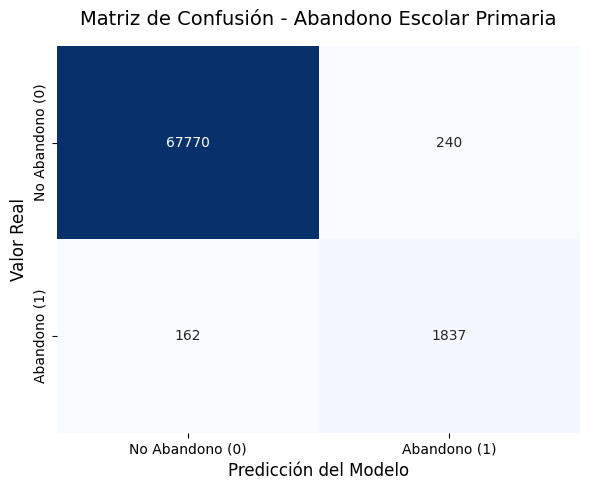

In [31]:
# 1. Calcular la matriz de confusión con el conjunto de prueba (X_test, y_test)
cm = confusion_matrix(y_test, y_pred)

# 2. Graficar con Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Abandono (0)', 'Abandono (1)'],
            yticklabels=['No Abandono (0)', 'Abandono (1)'])

plt.xlabel('Predicción del Modelo', fontsize=12)
plt.ylabel('Valor Real', fontsize=12)
plt.title('Matriz de Confusión - Abandono Escolar Primaria', fontsize=14, pad=15)
plt.tight_layout()

# Guardar y mostrar
plt.savefig('matriz_confusion_smote.png', dpi=300)
plt.show()

--- TOP VARIABLES MÁS IMPORTANTES ---
calif_bim1          0.491000
promedio_general    0.386710
faltas_b3           0.054145
calif_bim2          0.031252
calif_bim3          0.023336
faltas_totales      0.003275
grado               0.002416
turno               0.001749
faltas_b2           0.001493
reinscrito          0.001406
dtype: float64


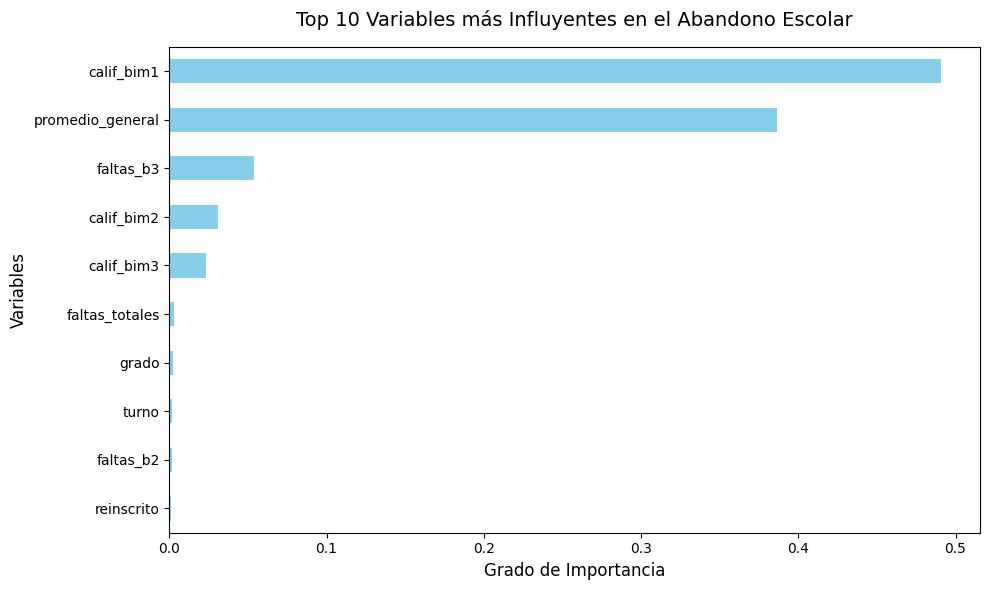

In [32]:
#(Feature Importances)
#  Obtener los importancias del modelo entrenado
importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- TOP VARIABLES MÁS IMPORTANTES ---")
print(importances.head(10))

# 2. Graficar las 10 variables más importantes
plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='skyblue')
plt.xlabel('Grado de Importancia', fontsize=12)
plt.ylabel('Variables', fontsize=12)
plt.title('Top 10 Variables más Influyentes en el Abandono Escolar', fontsize=14, pad=15)
plt.gca().invert_yaxis() # Para que la más importante quede arriba
plt.tight_layout()

# Guardar y mostrar
plt.savefig('importancia_variables.png', dpi=300)
plt.show()

In [33]:
# 1. (Opcional) Supongamos que tienes un nuevo archivo o un subconjunto de alumnos a los que quieres predecir el abandono
# Por ejemplo, cargamos un conjunto de nuevos datos o tomamos una muestra de prueba (X_test)
# nuevos_datos = pd.read_csv('nuevos_alumnos.csv')

# 1. Tomamos una muestra de prueba (por ejemplo, las primeras 5 filas del conjunto de prueba original X_test)
# Nota: Para esto, necesitamos conservar la CURP desde el DataFrame original antes de eliminarla para el modelo.
X_nuevos_con_curp = df_train_secu.loc[X_test.index].head(5).copy()

# 2. Extraemos la CURP para mostrarla después
curps_alumnos = X_nuevos_con_curp['curp']

# 3. Preparamos los datos exactamente igual que como entrenó el modelo (excluyendo curp y otras columnas no numéricas)
X_nuevos = X_nuevos_con_curp.drop(columns=['curp', 'cct', 'ciclo', 'tipo_movimiento', 'abandono'])

# Limpiar nulos (igual que en el entrenamiento)
numeric_cols = X_nuevos.select_dtypes(include=['int64', 'float64']).columns
X_nuevos[numeric_cols] = X_nuevos[numeric_cols].fillna(X_nuevos[numeric_cols].mean())

# 4. Hacer la predicción con el modelo entrenado (clf)
predicciones = clf.predict(X_nuevos)
probabilidades = clf.predict_proba(X_nuevos)

# 5. Crear un DataFrame con los resultados ordenados y claros
resultados = pd.DataFrame({
    'CURP': curps_alumnos,
    'Prediccion_Abandono': predicciones,
    'Probabilidad_Continuar': [prob[0] for prob in probabilidades],
    'Probabilidad_Abandono': [prob[1] for prob in probabilidades]
})

# Mostrar los resultados en pantalla
print("--- RESULTADOS DE PREDICCIÓN POR ALUMNO ---")
print(resultados.to_string(index=False))

--- RESULTADOS DE PREDICCIÓN POR ALUMNO ---
              CURP  Prediccion_Abandono  Probabilidad_Continuar  Probabilidad_Abandono
CACJ170620HCLSRSA6                    0                     1.0                    0.0
GUMI170612HDGTDKA9                    0                     1.0                    0.0
ROBC151013MCLDRHA3                    0                     1.0                    0.0
OASS161222MCLVLFA2                    0                     1.0                    0.0
LOLA150221MCLPPDA2                    0                     1.0                    0.0


In [34]:
# 1. Obtener las probabilidades de abandono para el conjunto de prueba (X_test)
# predict_proba() devuelve dos columnas: [Prob_No_Abandono, Prob_Abandono]
# Tomamos la columna 1 que corresponde a la probabilidad de abandono (de 0 a 1)
probabilidades_abandono = clf.predict_proba(X_test)[:, 1]

# 2. Función para clasificar la probabilidad en 3 grupos (Bajo, Medio, Alto)
def asignar_nivel_riesgo(prob):
    if prob < 0.33:
        return 'Bajo'
    elif prob < 0.66:
        return 'Medio'
    else:
        return 'Alto'

# Aplicar la clasificación a cada alumno
niveles_riesgo = [asignar_nivel_riesgo(p) for p in probabilidades_abandono]

# 3. Recuperar las CURPs correspondientes del conjunto de prueba
curps_prueba = df_train_secu.loc[X_test.index]['curp']

# 4. Crear un DataFrame final y ordenado con la métrica y los grupos
df_resultados_riesgo = pd.DataFrame({
    'CURP': curps_prueba,
    'Probabilidad_Abandono (0 a 1)': probabilidades_abandono.round(4),
    'Nivel_De_Riesgo': niveles_riesgo,
    'Real_Abandono': y_test.values
})

# Mostrar las primeras filas del reporte de riesgo
print("--- REPORTE DE RIESGO DE ABANDONO ESCOLAR ---")
print(df_resultados_riesgo.head(10).to_string(index=False))

# 5. Ver cuántos alumnos cayeron en cada categoría de riesgo
print("\n--- DISTRIBUCIÓN POR GRUPO DE RIESGO ---")
print(df_resultados_riesgo['Nivel_De_Riesgo'].value_counts())

--- REPORTE DE RIESGO DE ABANDONO ESCOLAR ---
              CURP  Probabilidad_Abandono (0 a 1) Nivel_De_Riesgo  Real_Abandono
CACJ170620HCLSRSA6                            0.0            Bajo              0
GUMI170612HDGTDKA9                            0.0            Bajo              0
ROBC151013MCLDRHA3                            0.0            Bajo              0
OASS161222MCLVLFA2                            0.0            Bajo              0
LOLA150221MCLPPDA2                            0.0            Bajo              0
AISI170613HCLVLNA3                            0.0            Bajo              0
PEZK170812MCLXMNA4                            0.0            Bajo              0
SAMG140627MCLLTRA6                            0.0            Bajo              0
GATY180122HHGLLHA9                            0.0            Bajo              0
MACI140719MCLRRLA7                            0.0            Bajo              0

--- DISTRIBUCIÓN POR GRUPO DE RIESGO ---
Nivel_De_Riesgo
Bajo 